# 29B — Refined Spatial + Wind Context for Emerging GeoMAE Anomalies
## Supervisor follow-up: reduce continuation-like candidates without over-filtering

### Why this revision exists

NB29 showed that a broad rule using **any prior hotspot within 3 days** and an `OR` condition for distance/wind was too aggressive: almost every robust anomaly could be linked to some prior hotspot.

This notebook uses a narrower question:

> **For a robust anomaly that is already classified as Emerging-3, is there a nearby hotspot on the immediately previous day (`t-1`) whose wind points toward the candidate?**

```text
GeoMAE robust anomaly
        ↓
Is it Emerging-3?
        ↓ yes
Look only at previous-day (t-1) hotspot sources
        ↓
close source AND wind aligned?
        ├─ yes → continuation-like context → deprioritize
        └─ no  → retain
                  ├─ no close source → spatially isolated / high priority
                  └─ close source but wind not supportive → ambiguous / retained
```

### Important interpretation

- This notebook does **not** create ground-truth false-positive labels.
- `continuation_like` means the event has a plausible nearby + wind-aligned previous-day context.
- `refined_high_priority` means an **Emerging-3 robust anomaly** with no hotspot source inside the immediate-neighbor radius on `t-1`.
- Wind is supporting evidence; **distance is the primary criterion**.
- `t-2` and `t-3` are reported only as secondary context and do not automatically remove a candidate.

### Primary settings fixed before seeing NB29B results

- immediate-neighbor radius: **40 km** — approximately the 3×3-neighborhood scale for a 0.25° grid;
- wind alignment threshold: **cosine ≥ 0.5** — source wind points within about 60° toward the target;
- primary continuation check: **t-1 only**;
- secondary context: **t-1 to t-3**.

A sensitivity table is also produced.

In [2]:
# 1. Imports

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 240)

In [3]:
# 2. Resolve project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root / "data" / "processed" / "regional_025" / "karhut_ml_dataset_regional_025.csv"
    )
    nb25_dir = (
        root / "model_results" / "final_masked_temporal_anomaly" / "t2" / "exports"
    )
    candidate_path = nb25_dir / "august_final_robust_anomaly_candidates.csv"
    analysis_path = nb25_dir / "august_hotspot_candidate_analysis.csv"

    if data_path.exists() and candidate_path.exists() and analysis_path.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional dataset + NB25 exports. "
        "Run from the skripsi-karhut project root or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed" / "regional_025" / "karhut_ml_dataset_regional_025.csv"
)
NB25_EXPORT_DIR = (
    PROJECT_ROOT / "model_results" / "final_masked_temporal_anomaly" / "t2" / "exports"
)
RESULT_DIR = (
    PROJECT_ROOT / "model_results" / "emerging_spatial_wind_refinement" / "t2"
)
EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"

EXPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR  :", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR  : c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2


In [4]:
# 3. Fixed working configuration

PRIMARY_SOURCE_LAG = 1
SECONDARY_LOOKBACK_DAYS = 3
NEAR_RADIUS_KM = 40.0
WIND_ALIGNMENT_THRESHOLD = 0.5
MIN_WIND_SPEED = 0.5

PREFERRED_TARGET_DATE = pd.Timestamp("2026-08-02")

print("PRIMARY_SOURCE_LAG       :", PRIMARY_SOURCE_LAG)
print("SECONDARY_LOOKBACK_DAYS :", SECONDARY_LOOKBACK_DAYS)
print("NEAR_RADIUS_KM           :", NEAR_RADIUS_KM)
print("WIND_ALIGNMENT_THRESHOLD:", WIND_ALIGNMENT_THRESHOLD)

PRIMARY_SOURCE_LAG       : 1
SECONDARY_LOOKBACK_DAYS : 3
NEAR_RADIUS_KM           : 40.0
WIND_ALIGNMENT_THRESHOLD: 0.5


In [5]:
# 4. Load regional data, robust candidates, and NB25 research-group labels

regional = pd.read_csv(DATA_PATH, parse_dates=["date"])
candidates = pd.read_csv(
    NB25_EXPORT_DIR / "august_final_robust_anomaly_candidates.csv",
    parse_dates=["date"],
)
analysis = pd.read_csv(
    NB25_EXPORT_DIR / "august_hotspot_candidate_analysis.csv",
    parse_dates=["event_date"],
)

required_regional = {
    "date", "cell_id", "grid_lat", "grid_lon",
    "fire_active", "fire_count", "frp_sum",
    "wind_u_mean", "wind_v_mean",
}
missing = sorted(required_regional - set(regional.columns))
if missing:
    raise ValueError(
        "Regional dataset is missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

required_candidate = {
    "date", "cell_id", "grid_lat", "grid_lon",
    "ensemble_median_rank", "high_seed_count",
}
missing = sorted(required_candidate - set(candidates.columns))
if missing:
    raise ValueError(
        "Candidate export is missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

if "research_group" not in analysis.columns:
    raise ValueError(
        "NB25 candidate analysis has no research_group column. "
        "Run NB23C/NB25 merge successfully first."
    )

group_info = (
    analysis[["event_date", "cell_id", "research_group"]]
    .drop_duplicates(["event_date", "cell_id"])
    .rename(columns={"event_date": "date"})
)

candidates = candidates.merge(
    group_info,
    on=["date", "cell_id"],
    how="left",
    validate="one_to_one",
)

regional = regional.sort_values(["date", "cell_id"]).reset_index(drop=True)
candidates = candidates.sort_values(["date", "cell_id"]).reset_index(drop=True)

print("Regional rows        :", len(regional))
print("Regional cells       :", regional["cell_id"].nunique())
print("All robust anomalies :", len(candidates))
print()
print("Robust candidate composition:")
display(
    candidates["research_group"]
    .value_counts(dropna=False)
    .rename_axis("research_group")
    .reset_index(name="robust_candidates")
)

Regional rows        : 16625
Regional cells       : 133
All robust anomalies : 620

Robust candidate composition:


,research_group,robust_candidates
0,Persistent,476
1,Emerging-3,118
2,NaN,26


# PART A — Restrict the refinement question to Emerging-3

A Persistent robust anomaly can still be scientifically interesting — for example an unexpectedly large fire magnitude — but it is **not** the same question as the supervisor's “a point suddenly appears far from the previous source” idea.

Therefore:
- all original robust anomalies remain preserved as GeoMAE output;
- this notebook refines only the **Emerging-3 robust-anomaly subset** for the new-isolated-hotspot question.

In [6]:
# 5. Emerging robust-anomaly subset

emerging = candidates[candidates["research_group"].eq("Emerging-3")].copy()
persistent = candidates[candidates["research_group"].eq("Persistent")].copy()
unknown = candidates[
    ~candidates["research_group"].isin(["Emerging-3", "Persistent"])
].copy()

print("All robust anomalies :", len(candidates))
print("Emerging-3 robust    :", len(emerging))
print("Persistent robust    :", len(persistent))
print("Unknown group        :", len(unknown))

if emerging.empty:
    raise RuntimeError("No Emerging-3 robust anomaly candidates were found.")

All robust anomalies : 620
Emerging-3 robust    : 118
Persistent robust    : 476
Unknown group        : 26


In [7]:
# 6. Geometry helpers

EARTH_RADIUS_KM = 6371.0088


def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    )

    return 2.0 * EARTH_RADIUS_KM * np.arcsin(
        np.sqrt(np.clip(a, 0.0, 1.0))
    )


def source_to_target_unit(source_lat, source_lon, target_lat, target_lon):
    mean_lat_rad = np.radians(
        (float(source_lat) + float(target_lat)) / 2.0
    )

    east_km = (
        (float(target_lon) - float(source_lon))
        * 111.320
        * np.cos(mean_lat_rad)
    )
    north_km = (
        (float(target_lat) - float(source_lat))
        * 110.574
    )

    norm = float(np.hypot(east_km, north_km))
    if norm == 0:
        return np.nan, np.nan

    return east_km / norm, north_km / norm


def wind_alignment(source_u, source_v, east_unit, north_unit):
    if not np.isfinite(east_unit) or not np.isfinite(north_unit):
        return np.nan

    magnitude = float(np.hypot(source_u, source_v))
    if not np.isfinite(magnitude) or magnitude < MIN_WIND_SPEED:
        return np.nan

    return float(
        (
            float(source_u) * float(east_unit)
            + float(source_v) * float(north_unit)
        )
        / magnitude
    )

In [8]:
# 7. Index active hotspot sources by date

active_sources = regional[regional["fire_active"].eq(1)].copy()
sources_by_date = {
    pd.Timestamp(date): group.copy()
    for date, group in active_sources.groupby("date")
}

print("Active source cell-days:", len(active_sources))

Active source cell-days: 3625


# PART B — Build previous-source evidence

The **primary** decision uses only `t-1`.

`t-2` and `t-3` are still calculated so the supervisor can see whether a candidate is isolated over a wider recent context, but these older sources do **not** automatically deprioritize the candidate.

In [9]:
# 8. Build source-candidate pairs for t-1, t-2, t-3

pair_rows = []

for cand in emerging.itertuples(index=False):
    cand_date = pd.Timestamp(cand.date)

    for lag in range(1, SECONDARY_LOOKBACK_DAYS + 1):
        source_date = cand_date - pd.Timedelta(days=lag)
        source_day = sources_by_date.get(source_date, pd.DataFrame())

        if source_day.empty:
            continue

        for src in source_day.itertuples(index=False):
            same_cell = src.cell_id == cand.cell_id

            distance_km = float(
                haversine_km(
                    src.grid_lat, src.grid_lon,
                    cand.grid_lat, cand.grid_lon,
                )
            )

            east_unit, north_unit = source_to_target_unit(
                src.grid_lat, src.grid_lon,
                cand.grid_lat, cand.grid_lon,
            )

            alignment = wind_alignment(
                src.wind_u_mean, src.wind_v_mean,
                east_unit, north_unit,
            )

            pair_rows.append({
                "candidate_date": cand_date,
                "candidate_cell_id": cand.cell_id,
                "candidate_lat": cand.grid_lat,
                "candidate_lon": cand.grid_lon,
                "candidate_anomaly_rank": cand.ensemble_median_rank,
                "candidate_high_seed_count": cand.high_seed_count,
                "source_date": source_date,
                "source_lag_days": lag,
                "source_cell_id": src.cell_id,
                "source_lat": src.grid_lat,
                "source_lon": src.grid_lon,
                "source_fire_count": src.fire_count,
                "source_frp_sum": src.frp_sum,
                "source_wind_u": src.wind_u_mean,
                "source_wind_v": src.wind_v_mean,
                "distance_km": distance_km,
                "wind_alignment": alignment,
                "same_cell_source": same_cell,
            })

pairs = pd.DataFrame(pair_rows)

if pairs.empty:
    raise RuntimeError("No prior hotspot-source pairs were found.")

print("Source-candidate pairs:", len(pairs))
print("Emerging candidates represented:", pairs["candidate_cell_id"].nunique())

same_cell_integrity = pairs[pairs["same_cell_source"]]
print("Same-cell recent source pairs among Emerging-3:", len(same_cell_integrity))

if len(same_cell_integrity):
    print(
        "WARNING: Emerging-3 has same-cell prior activity in the pair table. "
        "Inspect date alignment before interpreting refinement."
    )

Source-candidate pairs: 18636
Emerging candidates represented: 85
Same-cell recent source pairs among Emerging-3: 0


In [10]:
# 9. Candidate-level evidence

summary_rows = []

for cand in emerging.itertuples(index=False):
    cand_pairs = pairs[
        (pairs["candidate_date"].eq(pd.Timestamp(cand.date)))
        & (pairs["candidate_cell_id"].eq(cand.cell_id))
    ].copy()

    primary = cand_pairs[
        cand_pairs["source_lag_days"].eq(PRIMARY_SOURCE_LAG)
    ].copy()

    if len(primary):
        nearest_t1 = primary.sort_values("distance_km").iloc[0]
        nearest_t1_distance = float(nearest_t1["distance_km"])
        nearest_t1_cell = nearest_t1["source_cell_id"]
        nearest_t1_lat = float(nearest_t1["source_lat"])
        nearest_t1_lon = float(nearest_t1["source_lon"])
        nearest_t1_alignment = (
            float(nearest_t1["wind_alignment"])
            if pd.notna(nearest_t1["wind_alignment"])
            else np.nan
        )

        near_t1 = primary[primary["distance_km"] <= NEAR_RADIUS_KM].copy()
        aligned_near_t1 = near_t1[
            near_t1["wind_alignment"] >= WIND_ALIGNMENT_THRESHOLD
        ].copy()

        if len(aligned_near_t1):
            continuation_source = (
                aligned_near_t1
                .sort_values(
                    ["wind_alignment", "distance_km"],
                    ascending=[False, True],
                )
                .iloc[0]
            )

            cont_cell = continuation_source["source_cell_id"]
            cont_lat = float(continuation_source["source_lat"])
            cont_lon = float(continuation_source["source_lon"])
            cont_distance = float(continuation_source["distance_km"])
            cont_alignment = float(continuation_source["wind_alignment"])
        else:
            cont_cell = np.nan
            cont_lat = np.nan
            cont_lon = np.nan
            cont_distance = np.nan
            cont_alignment = np.nan

        has_close_t1 = bool(len(near_t1) > 0)
        continuation_like = bool(len(aligned_near_t1) > 0)
    else:
        nearest_t1_distance = np.nan
        nearest_t1_cell = np.nan
        nearest_t1_lat = np.nan
        nearest_t1_lon = np.nan
        nearest_t1_alignment = np.nan
        has_close_t1 = False
        continuation_like = False
        cont_cell = np.nan
        cont_lat = np.nan
        cont_lon = np.nan
        cont_distance = np.nan
        cont_alignment = np.nan

    if len(cand_pairs):
        nearest_prev3 = cand_pairs.sort_values("distance_km").iloc[0]
        nearest_prev3_distance = float(nearest_prev3["distance_km"])
        nearest_prev3_lag = int(nearest_prev3["source_lag_days"])

        recent_aligned = cand_pairs[
            (cand_pairs["distance_km"] <= NEAR_RADIUS_KM)
            & (cand_pairs["wind_alignment"] >= WIND_ALIGNMENT_THRESHOLD)
        ].copy()
        any_recent_close_aligned = bool(len(recent_aligned) > 0)
    else:
        nearest_prev3_distance = np.nan
        nearest_prev3_lag = np.nan
        any_recent_close_aligned = False

    # Distance is primary; wind only supports continuation.
    if not np.isfinite(nearest_t1_distance) or nearest_t1_distance > NEAR_RADIUS_KM:
        refinement_status = "spatially_isolated"
        refined_high_priority = True
        retained_after_refinement = True
    elif continuation_like:
        refinement_status = "continuation_like"
        refined_high_priority = False
        retained_after_refinement = False
    else:
        refinement_status = "nearby_but_wind_not_supportive"
        refined_high_priority = False
        retained_after_refinement = True

    summary_rows.append({
        "date": pd.Timestamp(cand.date),
        "cell_id": cand.cell_id,
        "grid_lat": cand.grid_lat,
        "grid_lon": cand.grid_lon,
        "ensemble_median_rank": cand.ensemble_median_rank,
        "high_seed_count": cand.high_seed_count,
        "research_group": "Emerging-3",
        "nearest_t1_hotspot_km": nearest_t1_distance,
        "nearest_t1_source_cell_id": nearest_t1_cell,
        "nearest_t1_source_lat": nearest_t1_lat,
        "nearest_t1_source_lon": nearest_t1_lon,
        "nearest_t1_wind_alignment": nearest_t1_alignment,
        "has_close_t1_source": has_close_t1,
        "continuation_like": continuation_like,
        "continuation_source_cell_id": cont_cell,
        "continuation_source_lat": cont_lat,
        "continuation_source_lon": cont_lon,
        "continuation_source_distance_km": cont_distance,
        "continuation_source_alignment": cont_alignment,
        "nearest_prev3_hotspot_km": nearest_prev3_distance,
        "nearest_prev3_hotspot_lag_days": nearest_prev3_lag,
        "any_close_wind_aligned_source_prev3": any_recent_close_aligned,
        "refinement_status": refinement_status,
        "retained_after_refinement": retained_after_refinement,
        "refined_high_priority": refined_high_priority,
    })

refined = pd.DataFrame(summary_rows)

print("Emerging robust candidates refined:", len(refined))

display(
    refined[
        [
            "date", "cell_id", "ensemble_median_rank",
            "nearest_t1_hotspot_km", "nearest_t1_wind_alignment",
            "refinement_status", "retained_after_refinement",
            "refined_high_priority",
        ]
    ]
    .sort_values(["date", "ensemble_median_rank"], ascending=[True, False])
    .head(40)
)

Emerging robust candidates refined: 118


,date,cell_id,ensemble_median_rank,nearest_t1_hotspot_km,nearest_t1_wind_alignment,refinement_status,retained_after_refinement,refined_high_priority
2,2026-08-02,regional025_8_32,1.000000,27.798770,-0.950029,nearby_but_wind_not_supportive,True,False
3,2026-08-02,regional025_9_31,0.984962,27.779653,-0.939690,nearby_but_wind_not_supportive,True,False
0,2026-08-02,regional025_12_31,0.969925,39.306647,0.943759,continuation_like,False,False
1,2026-08-02,regional025_13_22,0.924812,55.586823,0.946308,spatially_isolated,True,True
6,2026-08-04,regional025_5_22,0.977444,NaN,NaN,spatially_isolated,True,True
5,2026-08-04,regional025_12_28,0.939850,NaN,NaN,spatially_isolated,True,True
8,2026-08-04,regional025_8_23,0.932331,NaN,NaN,spatially_isolated,True,True
4,2026-08-04,regional025_12_27,0.924812,NaN,NaN,spatially_isolated,True,True
7,2026-08-04,regional025_5_31,0.894737,NaN,NaN,spatially_isolated,True,True
17,2026-08-05,regional025_5_29,0.992481,27.757433,-0.623387,nearby_but_wind_not_supportive,True,False


# PART C — Main result for supervision

The three groups have different meanings:

1. **Continuation-like**
   - there is a `t-1` hotspot source within 40 km;
   - at least one such nearby source has wind alignment ≥ 0.5 toward the candidate;
   - these are **deprioritized**, not declared false positives.

2. **Nearby but wind not supportive**
   - a nearby `t-1` hotspot exists;
   - wind does not support a source→candidate continuation explanation;
   - retained, but not called high-priority isolated.

3. **Spatially isolated**
   - no `t-1` hotspot source within 40 km;
   - these become the **refined high-priority** candidates.

In [11]:
# 10. Main counts

status_order = [
    "continuation_like",
    "nearby_but_wind_not_supportive",
    "spatially_isolated",
]

status_counts = (
    refined["refinement_status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

n_emerging = len(refined)
n_continuation = int(status_counts["continuation_like"])
n_ambiguous = int(status_counts["nearby_but_wind_not_supportive"])
n_isolated = int(status_counts["spatially_isolated"])
n_retained = int(refined["retained_after_refinement"].sum())

print("=== NB29B EMERGING SPATIAL-WIND REFINEMENT ===")
print()
print("All original robust anomalies             :", len(candidates))
print("Emerging-3 robust anomalies               :", n_emerging)
print("  Continuation-like → deprioritized       :", n_continuation)
print("  Nearby, wind not supportive → retained  :", n_ambiguous)
print("  Spatially isolated → high priority      :", n_isolated)
print()
print("Emerging retained after refinement        :", n_retained)
print("Emerging high-priority isolated candidates:", n_isolated)

summary_table = pd.DataFrame({
    "stage": [
        "All GeoMAE robust anomalies",
        "Emerging-3 robust anomalies",
        "Continuation-like (deprioritized)",
        "Nearby but wind not supportive (retained)",
        "Spatially isolated (high priority)",
    ],
    "count": [
        len(candidates),
        n_emerging,
        n_continuation,
        n_ambiguous,
        n_isolated,
    ],
})

display(summary_table)

=== NB29B EMERGING SPATIAL-WIND REFINEMENT ===

All original robust anomalies             : 620
Emerging-3 robust anomalies               : 118
  Continuation-like → deprioritized       : 71
  Nearby, wind not supportive → retained  : 33
  Spatially isolated → high priority      : 14

Emerging retained after refinement        : 47
Emerging high-priority isolated candidates: 14


,stage,count
0,All GeoMAE robust anomalies,620
1,Emerging-3 robust anomalies,118
2,Continuation-like (deprioritized),71
3,Nearby but wind not supportive (retained),33
4,Spatially isolated (high priority),14


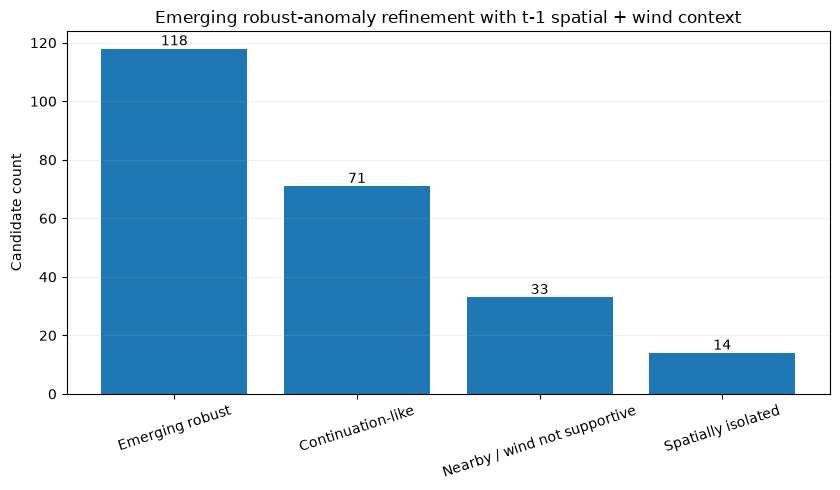

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\figures\01_emerging_refinement_counts.png


In [12]:
# 11. Simple count visualization

plot_df = pd.DataFrame({
    "category": [
        "Emerging robust",
        "Continuation-like",
        "Nearby / wind not supportive",
        "Spatially isolated",
    ],
    "count": [
        n_emerging,
        n_continuation,
        n_ambiguous,
        n_isolated,
    ],
})

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(plot_df["category"], plot_df["count"])
ax.set_ylabel("Candidate count")
ax.set_title("Emerging robust-anomaly refinement with t-1 spatial + wind context")
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="x", rotation=18)

for i, value in enumerate(plot_df["count"]):
    ax.text(i, value, str(int(value)), ha="center", va="bottom")

plt.tight_layout()
count_fig = FIGURE_DIR / "01_emerging_refinement_counts.png"
plt.savefig(count_fig, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", count_fig)

# PART D — Sensitivity analysis

This checks whether the conclusion depends strongly on the exact 40 km / 0.5 rule.

Only **Emerging-3 robust anomalies** and **t-1 sources** are used.

In [13]:
# 12. Sensitivity of continuation-like vs isolated classification

primary_pairs = pairs[pairs["source_lag_days"].eq(1)].copy()
sensitivity_rows = []

for radius in [30.0, 40.0, 50.0]:
    for align_threshold in [0.3, 0.5, 0.7]:
        continuation_flags = []
        isolated_flags = []
        ambiguous_flags = []

        for cand in emerging.itertuples(index=False):
            g = primary_pairs[
                (primary_pairs["candidate_date"].eq(pd.Timestamp(cand.date)))
                & (primary_pairs["candidate_cell_id"].eq(cand.cell_id))
            ]

            if len(g):
                nearest = float(g["distance_km"].min())
                near = g[g["distance_km"] <= radius]
                aligned_near = near[
                    near["wind_alignment"] >= align_threshold
                ]

                isolated = nearest > radius
                continuation = (not isolated) and len(aligned_near) > 0
                ambiguous = (not isolated) and not continuation
            else:
                isolated = True
                continuation = False
                ambiguous = False

            continuation_flags.append(continuation)
            isolated_flags.append(isolated)
            ambiguous_flags.append(ambiguous)

        sensitivity_rows.append({
            "near_radius_km": radius,
            "alignment_threshold": align_threshold,
            "emerging_candidates": len(emerging),
            "continuation_like": int(np.sum(continuation_flags)),
            "nearby_wind_not_supportive": int(np.sum(ambiguous_flags)),
            "spatially_isolated": int(np.sum(isolated_flags)),
            "isolated_fraction": float(np.mean(isolated_flags)),
        })

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,near_radius_km,alignment_threshold,emerging_candidates,continuation_like,nearby_wind_not_supportive,spatially_isolated,isolated_fraction
0,30.0,0.3,118,56,34,28,0.237288
1,30.0,0.5,118,46,44,28,0.237288
2,30.0,0.7,118,39,51,28,0.237288
3,40.0,0.3,118,78,26,14,0.118644
4,40.0,0.5,118,71,33,14,0.118644
5,40.0,0.7,118,60,44,14,0.118644
6,50.0,0.3,118,78,26,14,0.118644
7,50.0,0.5,118,71,33,14,0.118644
8,50.0,0.7,118,60,44,14,0.118644


# PART E — Before / after map

The figure keeps the original information visible rather than silently deleting candidates.

### Left
All original GeoMAE robust anomalies on the selected day.

### Right
Emerging robust anomalies are split into:
- `continuation_like` → deprioritized;
- `nearby_but_wind_not_supportive` → retained / ambiguous;
- `spatially_isolated` → refined high priority.

For continuation-like candidates, an arrow is drawn from the selected previous-day source to the candidate.

In [14]:
# 13. Choose visualization date

counts_by_date = refined.groupby("date").size().sort_values(ascending=False)

if PREFERRED_TARGET_DATE in set(refined["date"]):
    TARGET_DATE = PREFERRED_TARGET_DATE
else:
    TARGET_DATE = pd.Timestamp(counts_by_date.index[0])

print("TARGET_DATE:", TARGET_DATE.date())
print("Emerging robust candidates on date:", int(counts_by_date.loc[TARGET_DATE]))

TARGET_DATE: 2026-08-02
Emerging robust candidates on date: 4


In [15]:
# 14. Prepare visualization tables

day_all = regional[regional["date"].eq(TARGET_DATE)].copy()
day_hot = day_all[day_all["fire_active"].eq(1)].copy()
day_original = candidates[candidates["date"].eq(TARGET_DATE)].copy()
day_refined = refined[refined["date"].eq(TARGET_DATE)].copy()

day_cont = day_refined[
    day_refined["refinement_status"].eq("continuation_like")
].copy()
day_amb = day_refined[
    day_refined["refinement_status"].eq("nearby_but_wind_not_supportive")
].copy()
day_iso = day_refined[
    day_refined["refinement_status"].eq("spatially_isolated")
].copy()

print("Actual hotspot-positive cells:", len(day_hot))
print("All robust anomalies         :", len(day_original))
print("Emerging robust              :", len(day_refined))
print("Continuation-like            :", len(day_cont))
print("Nearby / wind not supportive:", len(day_amb))
print("Spatially isolated           :", len(day_iso))

Actual hotspot-positive cells: 35
All robust anomalies         : 21
Emerging robust              : 4
Continuation-like            : 1
Nearby / wind not supportive: 2
Spatially isolated           : 1


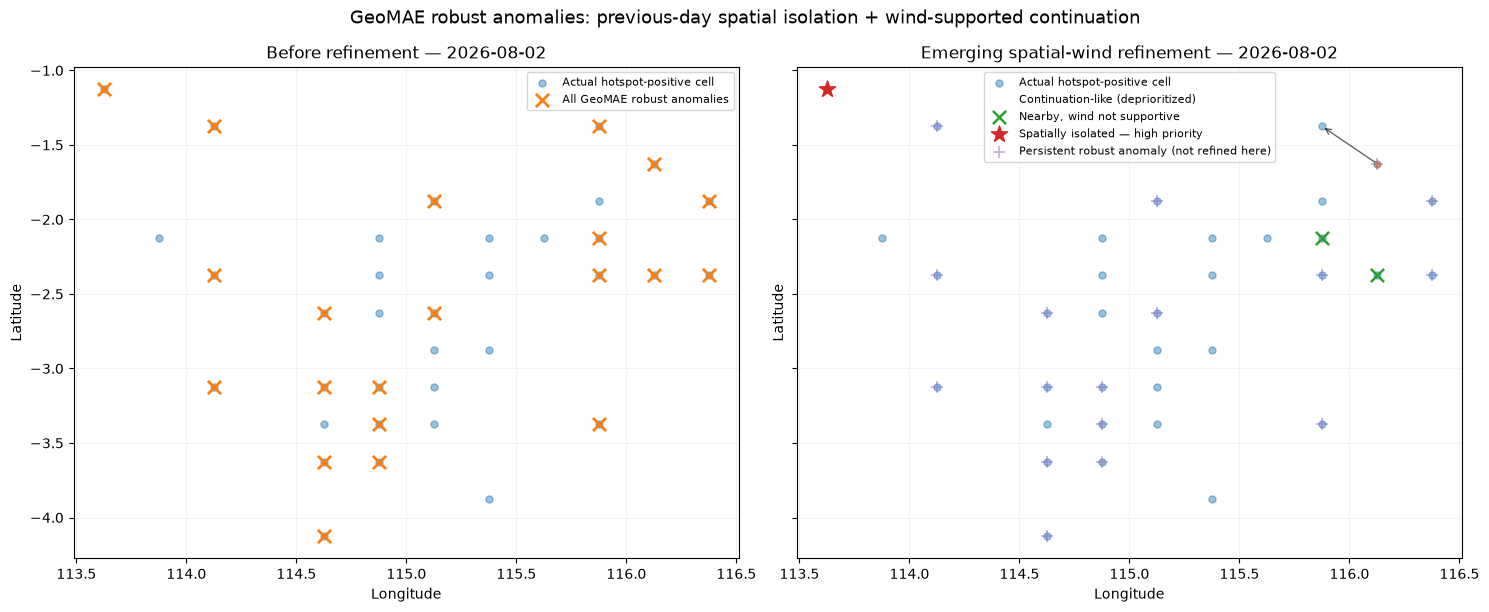

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\figures\02_before_after_emerging_refinement_2026-08-02.png


In [16]:
# 15. Before / after refinement map

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6.2), sharex=True, sharey=True
)
ax_before, ax_after = axes

for ax in axes:
    ax.scatter(
        day_hot["grid_lon"],
        day_hot["grid_lat"],
        s=26,
        alpha=0.45,
        label="Actual hotspot-positive cell",
    )

ax_before.scatter(
    day_original["grid_lon"],
    day_original["grid_lat"],
    marker="x",
    s=90,
    linewidths=2.0,
    label="All GeoMAE robust anomalies",
)
ax_before.set_title(f"Before refinement — {TARGET_DATE.date()}")

if len(day_cont):
    ax_after.scatter(
        day_cont["grid_lon"],
        day_cont["grid_lat"],
        marker="o",
        s=75,
        facecolors="none",
        linewidths=1.8,
        label="Continuation-like (deprioritized)",
    )

    for row in day_cont.itertuples(index=False):
        if pd.notna(row.continuation_source_lon) and pd.notna(row.continuation_source_lat):
            ax_after.annotate(
                "",
                xy=(row.grid_lon, row.grid_lat),
                xytext=(row.continuation_source_lon, row.continuation_source_lat),
                arrowprops={
                    "arrowstyle": "->",
                    "linewidth": 1.0,
                    "alpha": 0.6,
                },
            )
            ax_after.scatter(
                [row.continuation_source_lon],
                [row.continuation_source_lat],
                marker=".",
                s=55,
                alpha=0.8,
            )

if len(day_amb):
    ax_after.scatter(
        day_amb["grid_lon"],
        day_amb["grid_lat"],
        marker="x",
        s=90,
        linewidths=1.8,
        label="Nearby, wind not supportive",
    )

if len(day_iso):
    ax_after.scatter(
        day_iso["grid_lon"],
        day_iso["grid_lat"],
        marker="*",
        s=150,
        linewidths=1.0,
        label="Spatially isolated — high priority",
    )

day_persistent = day_original[
    day_original["research_group"].eq("Persistent")
]
if len(day_persistent):
    ax_after.scatter(
        day_persistent["grid_lon"],
        day_persistent["grid_lat"],
        marker="+",
        s=70,
        linewidths=1.2,
        alpha=0.55,
        label="Persistent robust anomaly (not refined here)",
    )

ax_after.set_title(
    f"Emerging spatial-wind refinement — {TARGET_DATE.date()}"
)

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.15)
    ax.legend(loc="best", fontsize=8)

fig.suptitle(
    "GeoMAE robust anomalies: previous-day spatial isolation + wind-supported continuation",
    fontsize=13,
)

plt.tight_layout()
map_path = FIGURE_DIR / f"02_before_after_emerging_refinement_{TARGET_DATE.date()}.png"
plt.savefig(map_path, dpi=210, bbox_inches="tight")
plt.show()
print("Saved:", map_path)

# PART F — Evidence table for supervision

Do not call `continuation_like` a confirmed false positive. Use:

> “This candidate is deprioritized because it has a nearby previous-day hotspot and the source-cell wind points toward the candidate.”

In [17]:
# 16. Evidence table for the selected date

presentation_cols = [
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "ensemble_median_rank",
    "high_seed_count",
    "nearest_t1_hotspot_km",
    "nearest_t1_source_cell_id",
    "nearest_t1_wind_alignment",
    "continuation_source_distance_km",
    "continuation_source_alignment",
    "nearest_prev3_hotspot_km",
    "nearest_prev3_hotspot_lag_days",
    "refinement_status",
    "retained_after_refinement",
    "refined_high_priority",
]

display(
    day_refined[presentation_cols]
    .sort_values(
        ["refined_high_priority", "ensemble_median_rank"],
        ascending=[False, False],
    )
)

,date,cell_id,grid_lat,grid_lon,ensemble_median_rank,high_seed_count,nearest_t1_hotspot_km,nearest_t1_source_cell_id,nearest_t1_wind_alignment,continuation_source_distance_km,continuation_source_alignment,nearest_prev3_hotspot_km,nearest_prev3_hotspot_lag_days,refinement_status,retained_after_refinement,refined_high_priority
1,2026-08-02,regional025_13_22,-1.125,113.625,0.924812,5,55.586823,regional025_13_24,0.946308,NaN,NaN,27.798770,2,spatially_isolated,True,True
2,2026-08-02,regional025_8_32,-2.375,116.125,1.000000,5,27.798770,regional025_9_32,-0.950029,NaN,NaN,27.774891,2,nearby_but_wind_not_supportive,True,False
3,2026-08-02,regional025_9_31,-2.125,115.875,0.984962,5,27.779653,regional025_9_30,-0.939690,NaN,NaN,27.779653,1,nearby_but_wind_not_supportive,True,False
0,2026-08-02,regional025_12_31,-1.375,115.875,0.969925,5,39.306647,regional025_11_32,0.943759,39.306647,0.943759,27.798770,2,continuation_like,False,False


In [18]:
# 17. Top high-priority isolated candidates across August

high_priority = (
    refined[refined["refined_high_priority"]]
    .sort_values(
        ["ensemble_median_rank", "high_seed_count", "nearest_t1_hotspot_km"],
        ascending=[False, False, False],
    )
    .copy()
)

print("High-priority isolated Emerging candidates:", len(high_priority))

display(
    high_priority[
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "ensemble_median_rank",
            "high_seed_count",
            "nearest_t1_hotspot_km",
            "nearest_t1_wind_alignment",
            "nearest_prev3_hotspot_km",
            "nearest_prev3_hotspot_lag_days",
        ]
    ].head(30)
)

High-priority isolated Emerging candidates: 14


,date,cell_id,grid_lat,grid_lon,ensemble_median_rank,high_seed_count,nearest_t1_hotspot_km,nearest_t1_wind_alignment,nearest_prev3_hotspot_km,nearest_prev3_hotspot_lag_days
6,2026-08-04,regional025_5_22,-3.125,113.625,0.977444,5,NaN,NaN,55.514865,2
47,2026-08-09,regional025_12_31,-1.375,115.875,0.969925,5,55.597540,0.868688,27.798770,3
5,2026-08-04,regional025_12_28,-1.375,115.125,0.939850,5,NaN,NaN,27.798770,3
12,2026-08-05,regional025_12_22,-1.375,113.625,0.932331,5,55.581531,-0.486694,27.798770,3
8,2026-08-04,regional025_8_23,-2.375,113.875,0.932331,5,NaN,NaN,27.774891,2
1,2026-08-02,regional025_13_22,-1.125,113.625,0.924812,5,55.586823,0.946308,27.798770,2
4,2026-08-04,regional025_12_27,-1.375,114.875,0.924812,5,NaN,NaN,27.790766,3
11,2026-08-05,regional025_11_33,-1.625,116.375,0.909774,5,62.136707,-0.034821,27.787590,3
7,2026-08-04,regional025_5_31,-3.125,115.875,0.894737,5,NaN,NaN,27.757433,3
27,2026-08-06,regional025_6_22,-2.875,113.625,0.864662,5,62.091758,0.717235,27.798770,2


In [19]:
# 18. Export outputs

REFINED_PATH = EXPORT_DIR / "august_emerging_spatial_wind_refined.csv"
HIGH_PRIORITY_PATH = EXPORT_DIR / "august_emerging_high_priority_isolated.csv"
PAIR_PATH = EXPORT_DIR / "emerging_candidate_prior_source_pairs.csv"
SENSITIVITY_PATH = EXPORT_DIR / "emerging_refinement_sensitivity.csv"
SUMMARY_PATH = EXPORT_DIR / "emerging_refinement_summary.csv"

refined.to_csv(REFINED_PATH, index=False)
high_priority.to_csv(HIGH_PRIORITY_PATH, index=False)
pairs.to_csv(PAIR_PATH, index=False)
sensitivity.to_csv(SENSITIVITY_PATH, index=False)
summary_table.to_csv(SUMMARY_PATH, index=False)

print("Saved:")
print("-", REFINED_PATH)
print("-", HIGH_PRIORITY_PATH)
print("-", PAIR_PATH)
print("-", SENSITIVITY_PATH)
print("-", SUMMARY_PATH)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\exports\august_emerging_spatial_wind_refined.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\exports\august_emerging_high_priority_isolated.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\exports\emerging_candidate_prior_source_pairs.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\exports\emerging_refinement_sensitivity.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\emerging_spatial_wind_refinement\t2\exports\emerging_refinement_summary.csv


# What to show the supervisor

Bring these outputs:

1. **NB29B main count table**
   - all robust anomalies;
   - Emerging-3 robust subset;
   - continuation-like candidates deprioritized;
   - nearby but wind-not-supportive candidates retained;
   - spatially isolated high-priority candidates.

2. **Before / after map**
   - original GeoMAE robust anomalies remain visible;
   - arrows show the previous-day source used for a continuation-like interpretation;
   - stars show spatially isolated high-priority Emerging candidates.

3. **Evidence table**
   - anomaly rank;
   - nearest `t-1` hotspot distance;
   - wind alignment;
   - final contextual status.

Suggested explanation:

> “Eksperimen filtering pertama terlalu agresif karena semua hotspot dalam tiga hari saya jadikan alasan untuk mengurangi anomaly. Saya revisi supaya fokus ke Emerging-3 dan sumber hotspot tepat satu hari sebelumnya. Jarak menjadi indikator utama, sedangkan arah angin hanya menjadi bukti pendukung continuation. Kandidat yang dekat sekaligus wind-aligned saya deprioritaskan. Kandidat yang tidak punya source dekat saya tandai sebagai spatially isolated high-priority anomaly. Jadi saya tidak menyebutnya ground-truth false positive, tetapi contextual refinement.”